# Retail Sales & Profitability Analysis
Descriptive analysis of order-level sales, profit and discounting for a retail business.

**Dataset:** `Retail_Sales_Cleaned.csv` (synthetic, order-level) | **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## 1. Setup and data loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("Retail_Sales_Cleaned.csv")
df.head()

,Order_ID,Order_Date,Region,Segment,Category,Sub_Category,Quantity,Unit_Price,Discount,Sales,Profit
0,ORD-1152,2024-01-01,South,Corporate,Office Supplies,Storage,2,60.26,0.10,108.47,11.82
1,ORD-1378,2024-01-05,North,Home Office,Technology,Accessories,1,42.79,0.20,34.23,6.19
2,ORD-1320,2024-01-14,North,Consumer,Office Supplies,Storage,5,58.75,0.10,264.38,30.18
3,ORD-1101,2024-01-14,North,Corporate,Furniture,Bookcases,2,186.95,0.40,224.34,-63.16
4,ORD-1240,2024-01-16,North,Consumer,Office Supplies,Storage,4,58.32,0.00,233.28,38.79


## 2. Data inspection

In [2]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}\n")
df.info()

Rows: 500 | Columns: 11

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      500 non-null    str    
 1   Order_Date    500 non-null    str    
 2   Region        500 non-null    str    
 3   Segment       500 non-null    str    
 4   Category      500 non-null    str    
 5   Sub_Category  500 non-null    str    
 6   Quantity      500 non-null    int64  
 7   Unit_Price    500 non-null    float64
 8   Discount      500 non-null    float64
 9   Sales         500 non-null    float64
 10  Profit        500 non-null    float64
dtypes: float64(4), int64(1), str(6)
memory usage: 43.1 KB


In [3]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Order_ID values:", df["Order_ID"].duplicated().sum())

Missing values per column:
Order_ID        0
Order_Date      0
Region          0
Segment         0
Category        0
Sub_Category    0
Quantity        0
Unit_Price      0
Discount        0
Sales           0
Profit          0
dtype: int64

Duplicate rows: 0
Duplicate Order_ID values: 0


In [4]:
df.describe()

,Quantity,Unit_Price,Discount,Sales,Profit
count,500.00,500.00,500.00,500.00,500.00
mean,3.87,177.76,0.11,649.80,81.60
std,1.99,207.51,0.12,940.54,222.14
min,1.00,13.50,0.00,8.17,-335.82
25%,2.00,26.76,0.00,89.05,3.05
50%,4.00,63.11,0.05,233.66,18.63
75%,6.00,257.25,0.20,792.38,54.79
max,7.00,768.85,0.40,"4,932.84","1,404.13"


## 3. Data validation and feature preparation

In [5]:
required = ["Order_ID", "Order_Date", "Region", "Segment", "Category", "Sub_Category",
            "Quantity", "Unit_Price", "Discount", "Sales", "Profit"]
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}"

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="raise")

assert df["Order_ID"].is_unique, "Order_ID must be unique"
assert df["Discount"].between(0, 1).all(), "Discount must be between 0 and 1"
assert (df["Quantity"] > 0).all() and (df["Sales"] > 0).all(), "Quantity and Sales must be positive"

expected_sales = df["Quantity"] * df["Unit_Price"] * (1 - df["Discount"])
assert ((df["Sales"] - expected_sales).abs() <= 0.01).all(), "Sales does not match Quantity x Unit_Price x (1 - Discount)"

df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Is_Loss"] = df["Profit"] < 0
df["Discount_Band"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.10, 0.20, 1.0],
                             labels=["0%", "1-10%", "11-20%", "21%+"])

print("All validation checks passed.")
print(f"Order dates: {df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}")

All validation checks passed.
Order dates: 2024-01-01 to 2025-12-31


## 4. Key performance indicators

In [6]:
total_orders = len(df)
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
profit_margin = total_profit / total_sales * 100
avg_order_value = total_sales / total_orders
loss_orders = int(df["Is_Loss"].sum())
loss_share = loss_orders / total_orders * 100

kpis = pd.DataFrame({
    "KPI": ["Total Orders", "Total Sales", "Total Profit", "Profit Margin",
            "Average Order Value", "Loss-making Orders", "Loss-making Share"],
    "Value": [f"{total_orders:,}", f"{total_sales:,.2f}", f"{total_profit:,.2f}", f"{profit_margin:.2f}%",
              f"{avg_order_value:,.2f}", f"{loss_orders:,}", f"{loss_share:.1f}%"]
})
kpis

,KPI,Value
0,Total Orders,500
1,Total Sales,"324,901.19"
2,Total Profit,"40,799.54"
3,Profit Margin,12.56%
4,Average Order Value,649.80
5,Loss-making Orders,108
6,Loss-making Share,21.6%


## 5. Performance by category and sub-category

In [7]:
def summarize(by):
    out = df.groupby(by).agg(Orders=("Order_ID", "count"),
                             Sales=("Sales", "sum"),
                             Profit=("Profit", "sum"))
    out["Profit_Margin_%"] = out["Profit"] / out["Sales"] * 100
    return out.sort_values("Profit", ascending=False)

by_category = summarize("Category")
by_category

,Orders,Sales,Profit,Profit_Margin_%
Category,,,,
Technology,155,"215,941.05","38,562.09",17.86
Office Supplies,211,"24,295.15","3,295.88",13.57
Furniture,134,"84,664.99","-1,058.43",-1.25


In [8]:
by_subcategory = summarize(["Category", "Sub_Category"])
by_subcategory

Orders      Sales    Profit  Profit_Margin_%
Category        Sub_Category                                              
Technology      Copiers           51 134,286.02 26,493.95            19.73
                Phones            51  73,644.08 10,473.96            14.22
                Accessories       53   8,010.95  1,594.18            19.90
Office Supplies Storage           78  15,360.98  1,495.09             9.73
Furniture       Chairs            42  16,221.52  1,166.22             7.19
Office Supplies Binders           73   5,833.87  1,117.03            19.15
                Paper             60   3,100.30    683.76            22.05
Furniture       Tables            43  40,779.11 -1,041.48            -2.55
                Bookcases         49  27,664.36 -1,183.17            -4.28

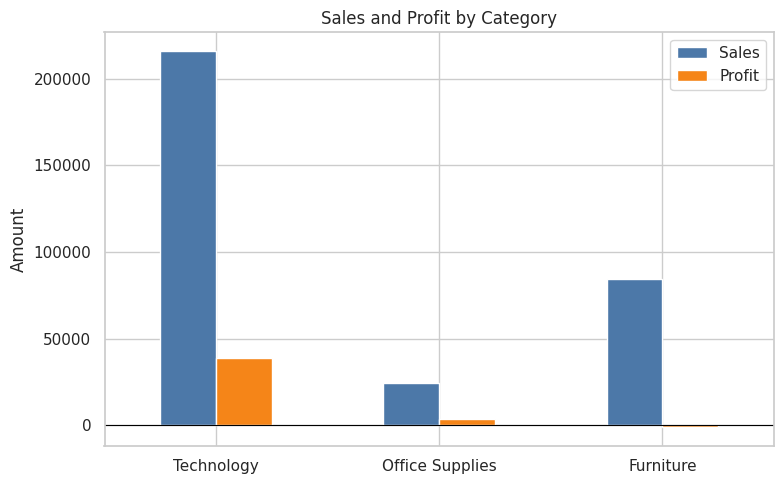

In [9]:
by_category[["Sales", "Profit"]].plot(kind="bar", figsize=(8, 5), color=["#4C78A8", "#F58518"])
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Sales and Profit by Category")
plt.xlabel("")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

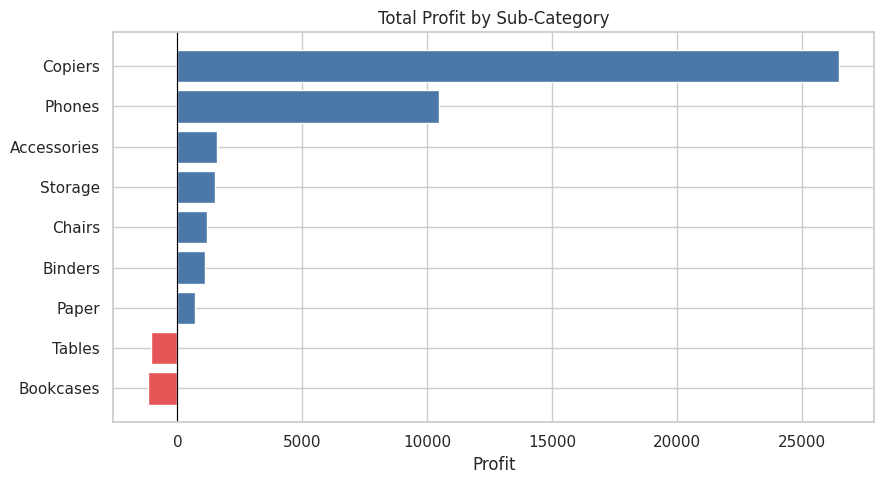

In [10]:
sub_plot = by_subcategory.reset_index().sort_values("Profit")
colors = np.where(sub_plot["Profit"] < 0, "#E45756", "#4C78A8")

plt.figure(figsize=(9, 5))
plt.barh(sub_plot["Sub_Category"], sub_plot["Profit"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Profit")
plt.tight_layout()
plt.show()

## 6. Performance by region and customer segment

In [11]:
by_region = summarize("Region")
by_segment = summarize("Segment")
display(by_region)
display(by_segment)

,Orders,Sales,Profit,Profit_Margin_%
Region,,,,
East,159,"107,456.06","13,365.22",12.44
North,128,"88,404.04","11,632.04",13.16
West,116,"70,351.83","8,628.80",12.27
South,97,"58,689.26","7,173.48",12.22


,Orders,Sales,Profit,Profit_Margin_%
Segment,,,,
Consumer,246,"167,873.51","22,003.47",13.11
Corporate,150,"95,664.90","11,399.32",11.92
Home Office,104,"61,362.78","7,396.75",12.05


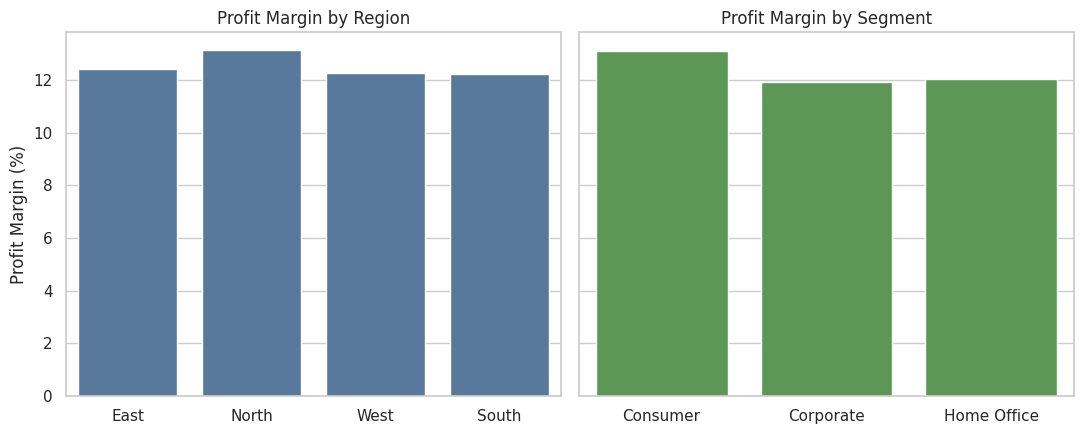

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
sns.barplot(x=by_region.index, y=by_region["Profit_Margin_%"], color="#4C78A8", ax=axes[0])
axes[0].set_title("Profit Margin by Region")
sns.barplot(x=by_segment.index, y=by_segment["Profit_Margin_%"], color="#54A24B", ax=axes[1])
axes[1].set_title("Profit Margin by Segment")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("Profit Margin (%)")
plt.tight_layout()
plt.show()

## 7. Monthly sales trend

In [13]:
monthly = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
monthly

Year,2024,2025
Month,,
1,"9,214.45","20,689.79"
2,"16,583.10","19,114.57"
3,"13,040.03","13,494.37"
4,"10,482.39","9,708.25"
5,"12,986.23","3,897.62"
6,"7,330.47","10,341.89"
7,"11,752.42","6,675.62"
8,"13,954.20","9,783.51"
9,"22,245.75","11,816.44"


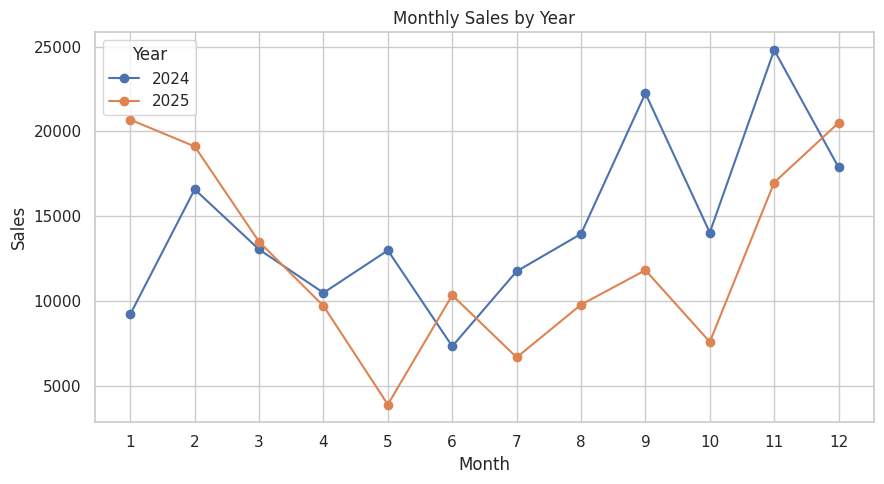

In [14]:
monthly.plot(marker="o", figsize=(9, 5))
plt.title("Monthly Sales by Year")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

## 8. Discount impact on profitability

In [15]:
by_discount = summarize("Discount").sort_index()
by_discount["Loss_Order_Share_%"] = df.groupby("Discount")["Is_Loss"].mean() * 100
by_discount

,Orders,Sales,Profit,Profit_Margin_%,Loss_Order_Share_%
Discount,,,,,
0.00,185,"150,596.18","31,000.90",20.59,0.54
0.05,89,"55,864.79","8,148.66",14.59,7.87
0.10,66,"40,004.70","4,585.31",11.46,19.70
0.20,78,"42,064.80",916.64,2.18,30.77
0.30,53,"25,296.33","-1,503.37",-5.94,64.15
0.40,29,"11,074.39","-2,348.60",-21.21,100.00


In [16]:
by_band = df.groupby("Discount_Band", observed=True).agg(Orders=("Order_ID", "count"),
                                                         Sales=("Sales", "sum"),
                                                         Profit=("Profit", "sum"))
by_band["Profit_Margin_%"] = by_band["Profit"] / by_band["Sales"] * 100
by_band

,Orders,Sales,Profit,Profit_Margin_%
Discount_Band,,,,
0%,185,"150,596.18","31,000.90",20.59
1-10%,155,"95,869.49","12,733.97",13.28
11-20%,78,"42,064.80",916.64,2.18
21%+,82,"36,370.72","-3,851.97",-10.59


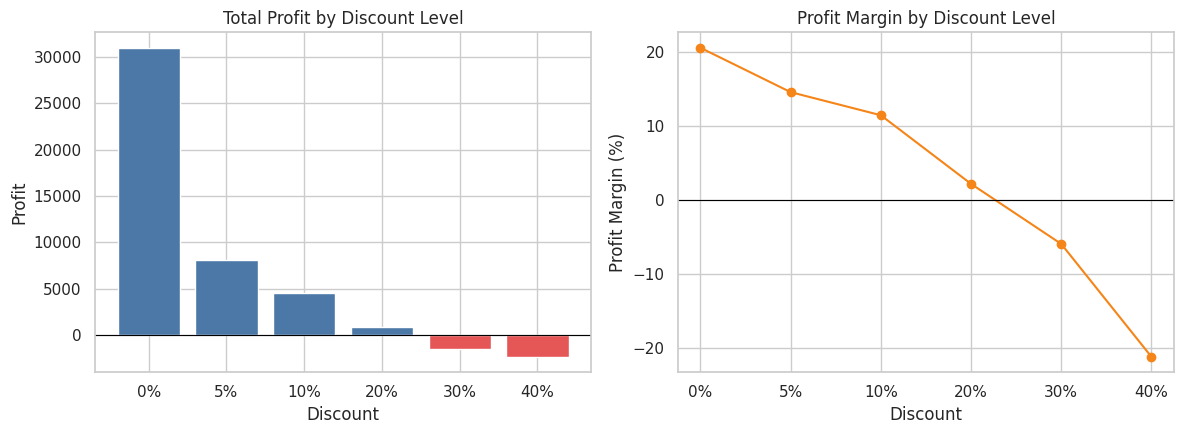

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colors = np.where(by_discount["Profit"] < 0, "#E45756", "#4C78A8")
axes[0].bar((by_discount.index * 100).astype(int).astype(str) + "%", by_discount["Profit"], color=colors)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title("Total Profit by Discount Level")
axes[0].set_xlabel("Discount")
axes[0].set_ylabel("Profit")

axes[1].plot((by_discount.index * 100).astype(int).astype(str) + "%", by_discount["Profit_Margin_%"],
             marker="o", color="#F58518")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Profit Margin by Discount Level")
axes[1].set_xlabel("Discount")
axes[1].set_ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

## 9. Data-derived insights

In [18]:
top_cat = by_category["Profit"].idxmax()
top_cat_sales_share = by_category.loc[top_cat, "Sales"] / total_sales * 100
top_cat_profit_share = by_category.loc[top_cat, "Profit"] / total_profit * 100
neg_cat = by_category[by_category["Profit"] < 0]
neg_sub = by_subcategory[by_subcategory["Profit"] < 0]
high_disc = df[df["Discount"] >= 0.30]
first_loss_level = by_discount[by_discount["Profit"] < 0].index.min()

print(f"1. Overall profit margin is {profit_margin:.2f}% on {total_sales:,.0f} in sales; "
      f"{loss_share:.1f}% of orders are loss-making.")
print(f"2. {top_cat} generates {top_cat_sales_share:.1f}% of sales and {top_cat_profit_share:.1f}% of profit.")
for name, row in neg_cat.iterrows():
    print(f"3. {name} has {row['Sales']:,.0f} in sales but a profit of {row['Profit']:,.0f} "
          f"({row['Profit_Margin_%']:.1f}% margin).")
print("4. Loss-making sub-categories: " + ", ".join(f"{c[1]} ({v:,.0f})" for c, v in neg_sub["Profit"].items()) + ".")
print(f"5. Profit turns negative from a {first_loss_level:.0%} discount; orders with a discount of 30% or more "
      f"are {len(high_disc) / total_orders * 100:.1f}% of orders, and {high_disc['Is_Loss'].mean() * 100:.1f}% of them lose money.")
print(f"6. Regional margins range from {by_region['Profit_Margin_%'].min():.1f}% to {by_region['Profit_Margin_%'].max():.1f}%; "
      f"segment margins from {by_segment['Profit_Margin_%'].min():.1f}% to {by_segment['Profit_Margin_%'].max():.1f}%.")
peak = df.groupby("Month")["Sales"].sum().nlargest(2).index.tolist()
print(f"7. Combined 2024-2025 sales peak in months {peak[0]} and {peak[1]}.")

1. Overall profit margin is 12.56% on 324,901 in sales; 21.6% of orders are loss-making.
2. Technology generates 66.5% of sales and 94.5% of profit.
3. Furniture has 84,665 in sales but a profit of -1,058 (-1.3% margin).
4. Loss-making sub-categories: Tables (-1,041), Bookcases (-1,183).
5. Profit turns negative from a 30% discount; orders with a discount of 30% or more are 16.4% of orders, and 76.8% of them lose money.
6. Regional margins range from 12.2% to 13.2%; segment margins from 11.9% to 13.1%.
7. Combined 2024-2025 sales peak in months 11 and 12.


## 10. Limitations
- The dataset is synthetic; the findings illustrate an analytical workflow and are not real business results.
- The analysis is descriptive. Associations between discount and profit do not establish causation.
- Each row is a single order line; customer-level behavior and repeat purchases cannot be analyzed.
- Two years of data are not enough to separate seasonality from one-off variation.